In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from matplotlib.colors import to_rgba
from appa2.grid import create_icosphere, latlon_to_xyz, PolarCapFilter
import math
from typing import Optional





In [18]:

def plot_icospheres(levels=(0, 1, 2), polar_cap_filter = None, elev=30, azim=-60, show_poles=True):
    fig = plt.figure(figsize=(5 * len(levels), 5))

    for panel, level in enumerate(levels, start=1):
        vertices, edges = create_icosphere(level, polar_cap_filter=polar_cap_filter)
        xyz = latlon_to_xyz(vertices).cpu().numpy()
        edges = edges.cpu().numpy()
        edges = np.unique(np.sort(edges, axis=1), axis=0)
        edges = edges[edges[:, 0] != edges[:, 1]]

        # Angular separation between connected vertices on the unit sphere.
        a, b = xyz[edges[:, 0]], xyz[edges[:, 1]]
        angles = np.arctan2(
            np.linalg.norm(np.cross(a, b), axis=1),
            np.sum(a * b, axis=1),
        )
        finest_km = angles.min() * 6371.0

        
        ax = fig.add_subplot(1, len(levels), panel, projection="3d")
        ax.view_init(elev=elev, azim=azim)


        el, az = np.radians([elev, azim])
        view_direction = np.array([
            np.cos(el) * np.cos(az),
            np.cos(el) * np.sin(az),
            np.sin(el),
        ])

        front = xyz @ view_direction >= 0

        colors = np.tile(to_rgba("tab:blue"), (len(xyz), 1))
        colors[:, 3] = np.where(front, 1.0, 0.15)

        ax.add_collection3d(
            Line3DCollection(xyz[edges], colors="gray", linewidths=0.5)
        )
        
        ax.scatter(*xyz.T, s=8, c=colors, depthshade=False)
        ax.set(xlim=(-1, 1), ylim=(-1, 1), zlim=(-1, 1),
            title = f"Subdivision {level}: {len(vertices)} vertices\n"
            f"Minimum spacing: {finest_km:.2f} km"
        )
        ax.set_box_aspect((1, 1, 1))
        ax.set_axis_off()

        if show_poles:
            ax.scatter(
                [0, 0], [0, 0], [1, -1],
                marker="*", s=100, color="red",
                depthshade=False, label="Poles",
            )
            ax.text(0, 0, 1.1, "N", ha="center", color="red")
            ax.text(0, 0, -1.1, "S", ha="center", color="red")

            if polar_cap_filter is not None:
                latitudes = np.linspace(-np.pi / 2, np.pi / 2, 361)

                for longitude in polar_cap_filter.longitudes:
                    lon = np.radians(longitude)

                    xyz_line = np.column_stack([
                        np.cos(latitudes) * np.cos(lon),
                        np.cos(latitudes) * np.sin(lon),
                        np.sin(latitudes),
                    ])

                    front_line = xyz_line @ view_direction >= 0

                    for visible, linestyle, alpha in [
                        (front_line, "-", 1.0),
                        (~front_line, ":", 0.25),
                    ]:
                        # NaNs break the line across hidden portions.
                        points = np.where(
                            visible[:, None], xyz_line, np.nan
                        )
                        ax.plot(
                            *points.T,
                            color="red",
                            linestyle=linestyle,
                            linewidth=1.0,
                            alpha=alpha,
                        )

    plt.tight_layout()
    plt.show()


def resolution(level, return_influence_radius_per_edge=False):
    vertices, edges = create_icosphere(level)
    xyz = latlon_to_xyz(vertices).cpu().numpy()
    edges = edges.cpu().numpy()
    edges = np.unique(np.sort(edges, axis=1), axis=0)
    edges = edges[edges[:, 0] != edges[:, 1]]

    # Angular separation between connected vertices on the unit sphere.
    a, b = xyz[edges[:, 0]], xyz[edges[:, 1]]
    angles = np.arctan2(
        np.linalg.norm(np.cross(a, b), axis=1),
        np.sum(a * b, axis=1),
    )
    finest_km = angles.min() * 6371.0
    if return_influence_radius_per_edge:
        influence_radius_per_edge = 6371.0 * 2 * math.asin(math.sqrt(1 / vertices.shape[0]))
        return finest_km, influence_radius_per_edge
    return finest_km




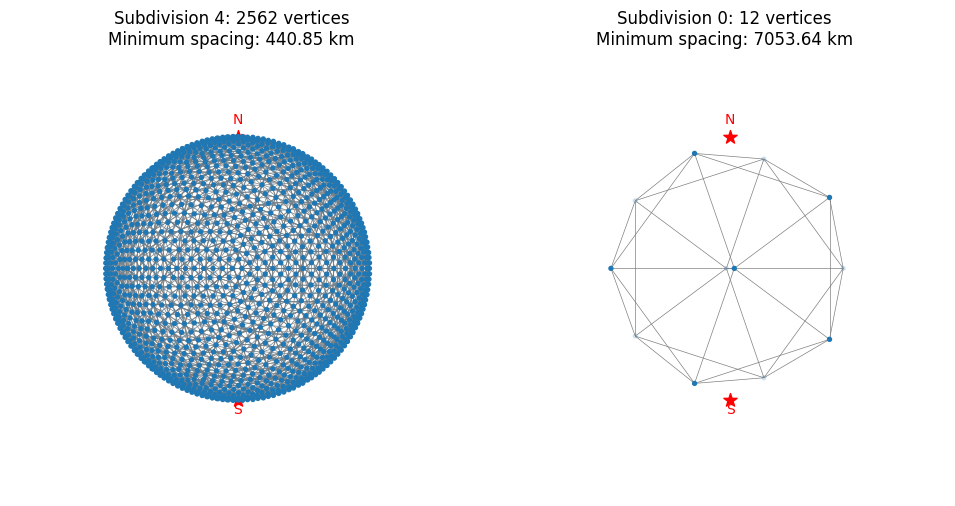

In [3]:
plot_icospheres((4,0), elev=0)

In [19]:
riops_filter = PolarCapFilter(
    longitudes=[-100, 100],
    latitudes=[43, 25],
)


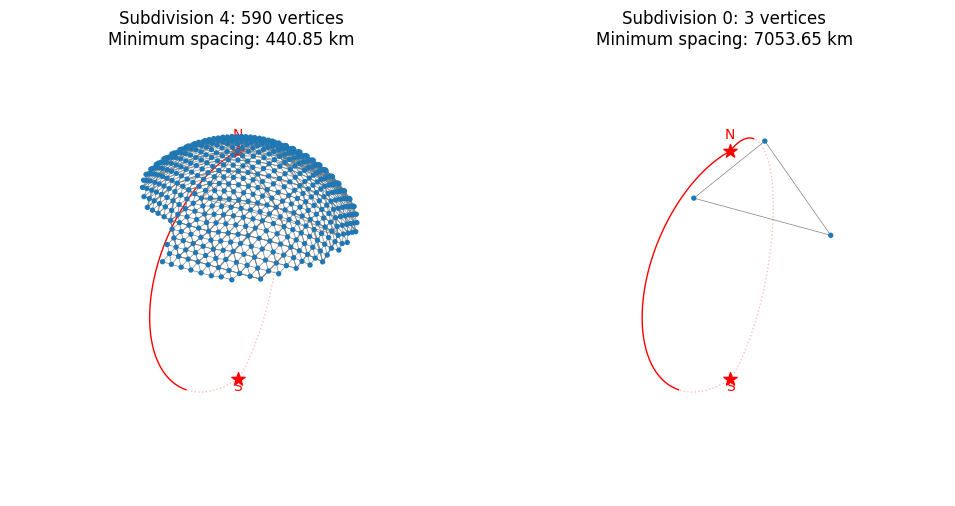

In [20]:
plot_icospheres((4,0), polar_cap_filter=riops_filter, elev=30)

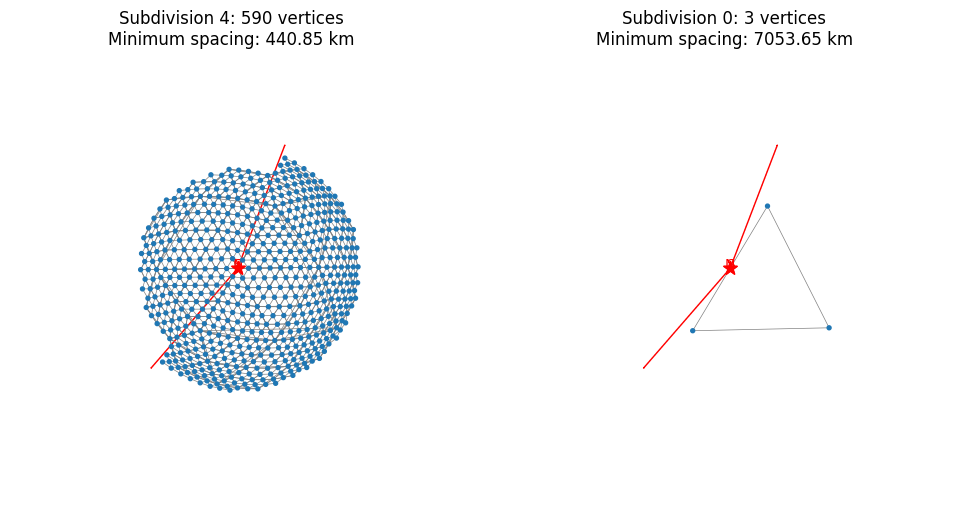

In [21]:
plot_icospheres((4,0), polar_cap_filter=riops_filter, elev=90)

In [22]:
riops_filter = PolarCapFilter(
    longitudes=[-100, 0, 100],
    latitudes=[43, 25, 0],
)


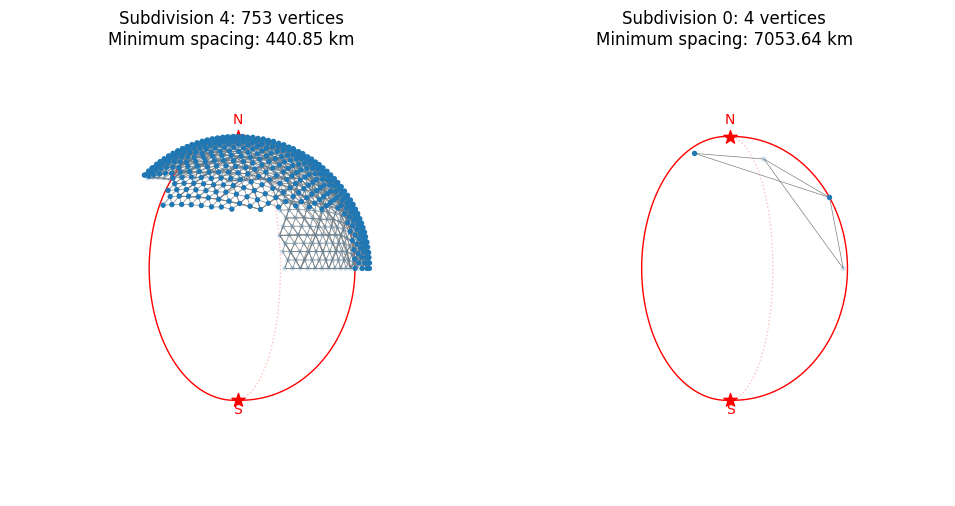

In [23]:
plot_icospheres((4,0), polar_cap_filter=riops_filter, elev=0)

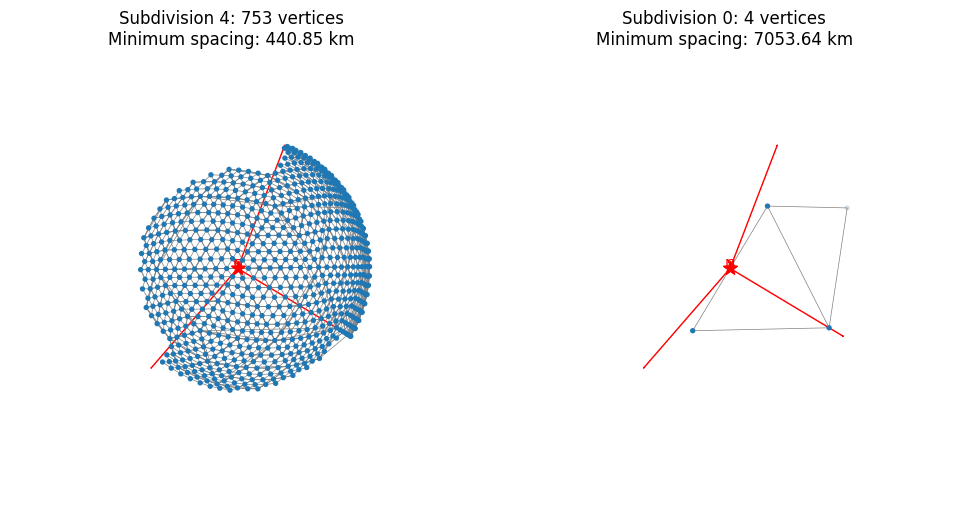

In [24]:
plot_icospheres((4,0), polar_cap_filter=riops_filter, elev=90)